# Team4

# Where Should Meridia Spend Its 2030 Retrofit Budget? 
*(A Three-Step Evidence Chain from Label Reliability to Retrofit Savings to Priority Targets)*

**Team:** A, B, C · **Dataset:** Building Energy Use

## 0. Milestone 1 card

1. **Research question:** Where should Meridia's City Council target its 2030 retrofit budget across building types, buildings and districts to maximize measured energy savings, given that energy labels may not reliably reflect actual energy intensity?  
   - SQ1: Within each building type, do A-G energy labels monotonically reflect actual energy intensity (kWh/m²), and how much do label distributions overlap? How do unknown-label buildings differ from assessed buildings?  
   - SQ2: Compared with matched un-renovated peers, how much do retrofitted buildings reduce total energy intensity and heating-related energy intensity in the 12 months after retrofit, after controlling for weather (HDD/CDD) and occupancy?  
   - SQ3: Among un-renovated buildings, which buildings and districts combine high measured energy intensity, large floor area and large saving potential, and should therefore be prioritised for the 2030 retrofit budget?
2. **Audience and decision:** Meridia Energy Agency & City Council — deciding where to direct the 2030 retrofit and solar budget.
3. **Link to the theme:** Energy-efficient buildings reduce running costs and improve indoor comfort — both direct drivers of liveability.
4. **Data card:** One row = one building × one month. 10,120 rows × 16 cols; 420 buildings × 24 months (Jan 2024 – Dec 2025) in 12 districts. Variables: `building_id`, `district_id`, `building_type`, `construction_year`, `floor_area_m2`, `energy_label`, `heating_system`, `has_solar_pv`, `retrofit_date`, `month`, `electricity_kwh`, `heating_kwh`, `solar_kwh`, `heating_degree_days`, `cooling_degree_days`, `occupancy_pct`.
5. **Data hygiene so far:** 40 duplicate rows → drop; ~1.5 % missing `electricity_kwh` → interpolate per building; `heating_kwh = 0` for heat pumps is expected; `energy_label = unknown` (21 buildings) kept but excluded from label charts; empty `occupancy_pct` for residential is by design.
6. **Visualisation plan:** SQ1 → faceted boxplot (static). SQ2 → interactive before/after line chart (Plotly). SQ3 → interactive bubble map + BI dashboard (Power BI).
7. **BI tool:** Power BI Desktop · teammate C · Windows.
8. **Team roles:** A — data & notebook · B — interactive figures & retrofit analysis · C — dashboard & storytelling.
9. **Two risks:** (1) Power BI not available on C's Mac → fallback to Tableau Public; (2) retrofit sub-sample too small → triangulate with boxplot before/after and confidence-free visual comparison.

## Setup

🧭 **What this cell does.** Imports the libraries and creates the four output folders that the whole team will use:
`data/`, `figures/static/`, `figures/interactive/`, `bi_export/`.
It also sets one shared visual style so that **every figure in the notebook looks like it belongs to the same report**.

👉 **What to do.** Run it once. You should see `Ready ✔`.

In [9]:
%pip install plotly
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import plotly.express as px
from pathlib import Path
from IPython.display import display

# ── Robust project-root detection ──────────────────────────────────────────
# VSCode's Jupyter working directory can be the *workspace root* or the folder
# of the .ipynb — we don't rely on either. We walk up until we find data/.
def find_project_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "data").is_dir():
            return p
    raise FileNotFoundError(
        f"Could not find a 'data/' folder above {start}.\n"
        f"Open the project root folder in VSCode (File → Open Folder), "
        f"or put building_energy_monthly.csv into a data/ folder next to the notebook."
    )

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
FIG_DIR  = PROJECT_ROOT / "figures" / "static"
INT_DIR  = PROJECT_ROOT / "figures" / "interactive"
BI_DIR   = PROJECT_ROOT / "bi_export"
for f in (FIG_DIR, INT_DIR, BI_DIR):
    f.mkdir(parents=True, exist_ok=True)

# ── Shared visual style (replaces the undefined apply_house_style) ─────────
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10, "axes.edgecolor": "#444444",
    "grid.color": "#e6e6e6",
    "axes.spines.top": False, "axes.spines.right": False,
})
LABEL_ORDER = ["A", "B", "C", "D", "E", "F", "G"]
TYPE_ORDER  = ["residential", "office", "school", "retail", "sports_centre"]

# ── Diagnostic print (useful when something goes wrong) ───────────────────
print(f"Project root : {PROJECT_ROOT}")
print(f"Data dir     : {DATA_DIR}")
print(f"CSV found    : {(DATA_DIR / 'building_energy_monthly.csv').exists()}")
print(f"pandas {pd.__version__} | seaborn {sns.__version__}")
print("Ready ✔")

Note: you may need to restart the kernel to use updated packages.
Project root : d:\Data Visualization\my_project
Data dir     : d:\Data Visualization\my_project\data
CSV found    : True
pandas 3.0.6 | seaborn 0.13.2
Ready ✔



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Part 1: Data Loading & Hygiene
## 1.1 Load & first look

🧭 **What this cell does.**
- Reads `building_energy_monthly.csv` and parses `month` as a real date.
- Prints the shape, the column types, and the **first two rows**.
- Runs three first checks: number of duplicated rows, number of missing values per column, date range covered.

👉 **What to look for.** The brief warns about **40 duplicated rows** and **~1.5 % missing electricity readings** — both should show up here.

In [10]:
raw = pd.read_csv(DATA_DIR / "building_energy_monthly.csv", parse_dates=["month"])

print(f"Shape: {raw.shape}  ({raw.shape[0]:,} building-months × {raw.shape[1]} columns)")
print(f"Period: {raw['month'].min().date()} → {raw['month'].max().date()}")
print(f"Buildings: {raw['building_id'].nunique()}   Districts: {raw['district_id'].nunique()}")

# First data-quality checks (before touching anything)
print(f"\nDuplicated rows (all columns identical): {raw.duplicated().sum()}")
print(f"Duplicated (building_id, month) pairs   : {raw.duplicated(subset=['building_id','month']).sum()}")
print("\nMissing values per column (%):")
display((raw.isna().mean() * 100).round(2).to_frame("% missing").T)

display(raw.head(2))

Shape: (10120, 16)  (10,120 building-months × 16 columns)
Period: 2024-01-01 → 2025-12-01
Buildings: 420   Districts: 12

Duplicated rows (all columns identical): 40
Duplicated (building_id, month) pairs   : 40

Missing values per column (%):


,building_id,district_id,building_type,construction_year,floor_area_m2,energy_label,heating_system,has_solar_pv,retrofit_date,month,electricity_kwh,heating_kwh,solar_kwh,heating_degree_days,cooling_degree_days,occupancy_pct
% missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,89.51,0.0,1.5,0.0,0.0,0.0,0.0,47.65


,building_id,district_id,building_type,construction_year,floor_area_m2,energy_label,heating_system,has_solar_pv,retrofit_date,month,electricity_kwh,heating_kwh,solar_kwh,heating_degree_days,cooling_degree_days,occupancy_pct
0,BLD0001,D02,residential,1983,6520.0,F,district_heating,False,NaN,2024-01-01,18138.0,241249.0,0.0,378.9,0.0,NaN
1,BLD0001,D02,residential,1983,6520.0,F,district_heating,False,NaN,2024-02-01,19113.0,225155.0,0.0,357.9,0.0,NaN


### ✍️ Observe #1
1. Why is `duplicated()` (all columns) enough here, and when would you need `subset=['building_id','month']`?
2. Which three columns have missing values, and is that expected?
3. Why is `heating_kwh = 0` for heat-pump buildings **not** an error?

📖 **Conclusion.**
- 40 rows are *identical duplicates* — removing them with `drop_duplicates()` (no argument) is safe and correct here, because the brief says they are "identical values".
- `electricity_kwh` is the only variable column with ~1.5 % missing → we will fill it **per building**, not with a global mean (otherwise a small school and a large office would get the same fill value).
- `occupancy_pct` is missing for all residential buildings — this is by design, we do **not** fill it.
- `heating_kwh = 0` for heat pumps is expected: heat-pump heating is inside `electricity_kwh`. We will **not** treat it as missing.

## 1.2 Cleaning pipeline

🧭 **What this cell does.** Six explicit steps, each logged:

| # | Step | Why |
|---|---|---|
| 1 | `drop_duplicates()` | 40 identical rows would double-count some building-months |
| 2 | Convert `month` to datetime | Needed for any time-based grouping |
| 3 | Sort by `(building_id, month)` | Required before per-building time interpolation |
| 4 | Fill missing `electricity_kwh` per building (linear interpolation between months, then that building's mean as fallback) | The brief says meters "were not read that month"; the neighbouring months are the best available estimate |
| 5 | Compute `Total_Energy = electricity_kwh + heating_kwh` | **This is a deliberate assumption**: we are adding purchased electricity and purchased heat (both in kWh) to measure *dependency on the energy system*. We state it in the figure caption. |
| 6 | Compute `Energy_Intensity = Total_Energy / floor_area_m2` | Lets us compare buildings of different sizes. Per the brief: *compute it as total kWh ÷ total m², not as an average of ratios* (later, when aggregating). |

⚠️ **Order matters:** we fill `electricity_kwh` **before** computing `Total_Energy`, otherwise `Energy_Intensity` would be `NaN` for the ~1.5 % missing months.

In [11]:
df = raw.copy()

# 1) Deduplicate
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_dupes_removed = n_before - len(df)

# 2) Ensure date type (already parsed, but defensive)
df["month"] = pd.to_datetime(df["month"])

# 3) Sort so that per-building time interpolation works
df = df.sort_values(["building_id", "month"]).reset_index(drop=True)

# 4) Fill missing electricity per building: linear interpolation + mean fallback
n_missing_elec = int(df["electricity_kwh"].isna().sum())
df["electricity_kwh"] = (
    df.groupby("building_id")["electricity_kwh"]
      .transform(lambda s: s.interpolate(method="linear", limit_direction="both")
                            .fillna(s.mean()))
)

# 5) Total purchased energy  (electricity + purchased heat, both in kWh)
df["Total_Energy"] = df["electricity_kwh"] + df["heating_kwh"]

# 6) Energy intensity at the building-month level
df["Energy_Intensity"] = df["Total_Energy"] / df["floor_area_m2"]

print(f"Rows before cleaning: {n_before:,}")
print(f"Duplicates removed  : {n_dupes_removed}")
print(f"Missing electricity values interpolated: {n_missing_elec}")
print(f"Final shape: {df.shape}  ·  NaN in Total_Energy: {int(df['Total_Energy'].isna().sum())}")
display(df[["building_id", "building_type", "energy_label", "month",
            "electricity_kwh", "heating_kwh", "Total_Energy", "Energy_Intensity"]].head(3))

Rows before cleaning: 10,120
Duplicates removed  : 40
Missing electricity values interpolated: 151
Final shape: (10080, 18)  ·  NaN in Total_Energy: 0


,building_id,building_type,energy_label,month,electricity_kwh,heating_kwh,Total_Energy,Energy_Intensity
0,BLD0001,residential,F,2024-01-01,18138.0,241249.0,259387.0,39.783282
1,BLD0001,residential,F,2024-02-01,19113.0,225155.0,244268.0,37.464417
2,BLD0001,residential,F,2024-03-01,18538.0,138915.0,157453.0,24.149233


## 1.3 Decision log

🧭 **What this cell does.** Records every cleaning decision in a single table. This table is what your mentor will look at to check that **nothing was silently changed**.

The two "kept as-is" rows are just as important as the two "dropped/filled" rows.

In [12]:
decision_log = pd.DataFrame([
    ("Duplicate rows (all columns identical)", n_dupes_removed, "Dropped",
     "Identical duplicates would double-count the same building-month"),
    ("Missing electricity_kwh (~1.5 %)", n_missing_elec, "Filled per building (linear interp. + mean fallback)",
     "Neighbouring months are the best estimate; a global mean would distort small vs large buildings"),
    ("heating_kwh = 0 for heat-pump buildings", "~all heat-pump rows", "Kept as-is",
     "Not an error: heat-pump heating is inside electricity_kwh"),
    ("energy_label = 'unknown' (21 buildings)", 21, "Kept in df, excluded from label charts",
     "Real information, but cannot be ordered A→G"),
    ("occupancy_pct empty for residential", "all residential rows", "Kept as-is",
     "By design — occupancy only recorded for non-residential buildings"),
], columns=["Issue", "Rows affected", "Decision", "Reason"])
display(decision_log)

,Issue,Rows affected,Decision,Reason
0,Duplicate rows (all columns identical),40,Dropped,Identical duplicates would double-count the sa...
1,Missing electricity_kwh (~1.5 %),151,Filled per building (linear interp. + mean fal...,Neighbouring months are the best estimate; a g...
2,heating_kwh = 0 for heat-pump buildings,~all heat-pump rows,Kept as-is,Not an error: heat-pump heating is inside elec...
3,energy_label = 'unknown' (21 buildings),21,"Kept in df, excluded from label charts","Real information, but cannot be ordered A→G"
4,occupancy_pct empty for residential,all residential rows,Kept as-is,By design — occupancy only recorded for non-re...


## 1.4 Data-quality verification

🧭 **What this cell does.** Three quick checks:
1. No more duplicates, no more missing electricity, no NaN energy intensity.
2. Every building has exactly 24 months.
3. Compare the mean intensity by label — a quick sanity check *before* Experiment 1.

In [13]:
checks = pd.DataFrame({
    "Duplicates remaining":          [int(df.duplicated().sum())],
    "Missing electricity_kwh":       [int(df["electricity_kwh"].isna().sum())],
    "Missing Total_Energy":          [int(df["Total_Energy"].isna().sum())],
    "Missing Energy_Intensity":      [int(df["Energy_Intensity"].isna().sum())],
})
display(checks.T.rename(columns={0: "count"}))

months_per_building = df.groupby("building_id")["month"].nunique()
print(f"Months per building — min={months_per_building.min()}, max={months_per_building.max()}, "
      f"median={months_per_building.median()}")

print("\nMean Energy_Intensity by label (should decrease A→G if the labels are honest):")
display(df.groupby("energy_label")["Energy_Intensity"].mean().reindex(LABEL_ORDER + ["unknown"]).round(2).to_frame("mean kWh/m²"))

,count
Duplicates remaining,0
Missing electricity_kwh,0
Missing Total_Energy,0
Missing Energy_Intensity,0


Months per building — min=24, max=24, median=24.0

Mean Energy_Intensity by label (should decrease A→G if the labels are honest):


,mean kWh/m²
energy_label,
A,9.14
B,10.26
C,12.54
D,15.14
E,16.93
F,19.02
G,24.03
unknown,13.27


## 1.5 Export for BI & downstream teammates

🧭 **What this cell does.** Writes **three** CSVs that the whole team will use:

| File | Used by | What it contains |
|---|---|---|
| `bi_export/building_monthly_clean.csv` | C (Power BI) | The clean panel (one row per building-month) |
| `bi_export/building_summary.csv` | B & C | One row per building, with 24-month totals, intensity, solar share, retrofit flag |
| `bi_export/district_summary.csv` | C | One row per district, with totals and per-capita rates (from `districts.csv`) |

The district summary uses `population_2024` to compute **rates**, not raw counts — the brief explicitly asks for this.

In [14]:
# (a) Clean building-month panel
df.to_csv(BI_DIR / "building_monthly_clean.csv", index=False)

# (b) Building-level summary
building_summary = (
    df.groupby(["building_id", "district_id", "building_type", "energy_label",
                "heating_system", "has_solar_pv", "retrofit_date", "floor_area_m2",
                "construction_year"], dropna=False)
      .agg(total_energy_kwh=("Total_Energy", "sum"),
           total_electricity_kwh=("electricity_kwh", "sum"),
           total_heating_kwh=("heating_kwh", "sum"),
           total_solar_kwh=("solar_kwh", "sum"),
           months_observed=("month", "nunique"))
      .reset_index()
)
building_summary["energy_intensity_kwh_m2"] = building_summary["total_energy_kwh"] / building_summary["floor_area_m2"]
building_summary["has_retrofit"] = building_summary["retrofit_date"].notna()
building_summary["solar_share_of_electricity"] = np.where(
    building_summary["total_electricity_kwh"] + building_summary["total_solar_kwh"] > 0,
    building_summary["total_solar_kwh"] / (building_summary["total_electricity_kwh"] + building_summary["total_solar_kwh"]),
    np.nan)
building_summary.to_csv(BI_DIR / "building_summary.csv", index=False)

# (c) District summary with population-based rates
districts = pd.read_csv(DATA_DIR / "districts.csv")

district_summary = (
    building_summary.groupby("district_id")
      .agg(n_buildings=("building_id", "nunique"),
           total_energy_kwh=("total_energy_kwh", "sum"),
           total_floor_area_m2=("floor_area_m2", "sum"),
           total_solar_kwh=("total_solar_kwh", "sum"))
      .reset_index()
      .merge(districts[["district_id", "district_name", "population_2024"]],
             on="district_id", how="left")
)

# 加权强度：sum(energy) / sum(floor area)，不是 mean(ratio)
district_summary["mean_energy_intensity"] = (
    district_summary["total_energy_kwh"] / district_summary["total_floor_area_m2"]
)
district_summary["energy_per_capita_kwh"] = (
    district_summary["total_energy_kwh"] / district_summary["population_2024"]
)

district_summary.to_csv(BI_DIR / "district_summary.csv", index=False)

print("Exported:")
for p in sorted(BI_DIR.glob("*.csv")):
    print(f"  {p}  ({p.stat().st_size/1024:.0f} KB)")
print(f"\nRows in building_monthly_clean : {len(df):,}")
print(f"Rows in building_summary       : {len(building_summary)}")
print(f"Rows in district_summary       : {len(district_summary)}")
display(district_summary.head())

Exported:
  d:\Data Visualization\my_project\bi_export\building_monthly_clean.csv  (1255 KB)
  d:\Data Visualization\my_project\bi_export\building_summary.csv  (51 KB)
  d:\Data Visualization\my_project\bi_export\district_summary.csv  (1 KB)

Rows in building_monthly_clean : 10,080
Rows in building_summary       : 420
Rows in district_summary       : 12


,district_id,n_buildings,total_energy_kwh,total_floor_area_m2,total_solar_kwh,district_name,population_2024,mean_energy_intensity,energy_per_capita_kwh
0,D01,25,39124801.5,129156.0,563088.0,Greenhill,95000,302.926705,411.840016
1,D02,51,117028187.0,352642.0,1174383.0,Northgate,210000,331.861171,557.277081
2,D03,37,76717263.0,242097.0,967850.0,University Park,120000,316.886467,639.310525
3,D04,14,55744094.0,133821.0,436837.0,Eastport,85000,416.557147,655.812871
4,D05,35,71124353.0,237916.0,1383166.0,Westfield,110000,298.947330,646.585027


## Part 2: Experiment 1 — Are Meridia's Energy Labels Trustworthy?
## 2.1 Why the current label system cannot be used to allocate money

The city council's first instinct is simple: *"give the 2030 retrofit budget to buildings labelled F or G."*
Before spending a euro, we test **whether the label is even a good proxy for real energy intensity**.

**We compare, for each building type, the actual 24-month energy intensity (kWh/m²) of buildings by label (A → G).**
If the labels are reliable, the boxes should fall **monotonically** from A to G in every type.

**Why we aggregate to the building level first (not month-by-month).** The energy label describes a *building*, not a month.
A building-month figure would mix the label signal with summer/winter noise. Aggregating 24 months into one point per building gives the label the strongest possible chance to show itself.
Intensity is computed as **total kWh ÷ total m²** over the two years, as the brief requires.

⚠️ **Excluded from the chart:** the 21 buildings with `energy_label = 'unknown'` (cannot be placed on the A→G axis). They are kept in `df` for later use by B and C.

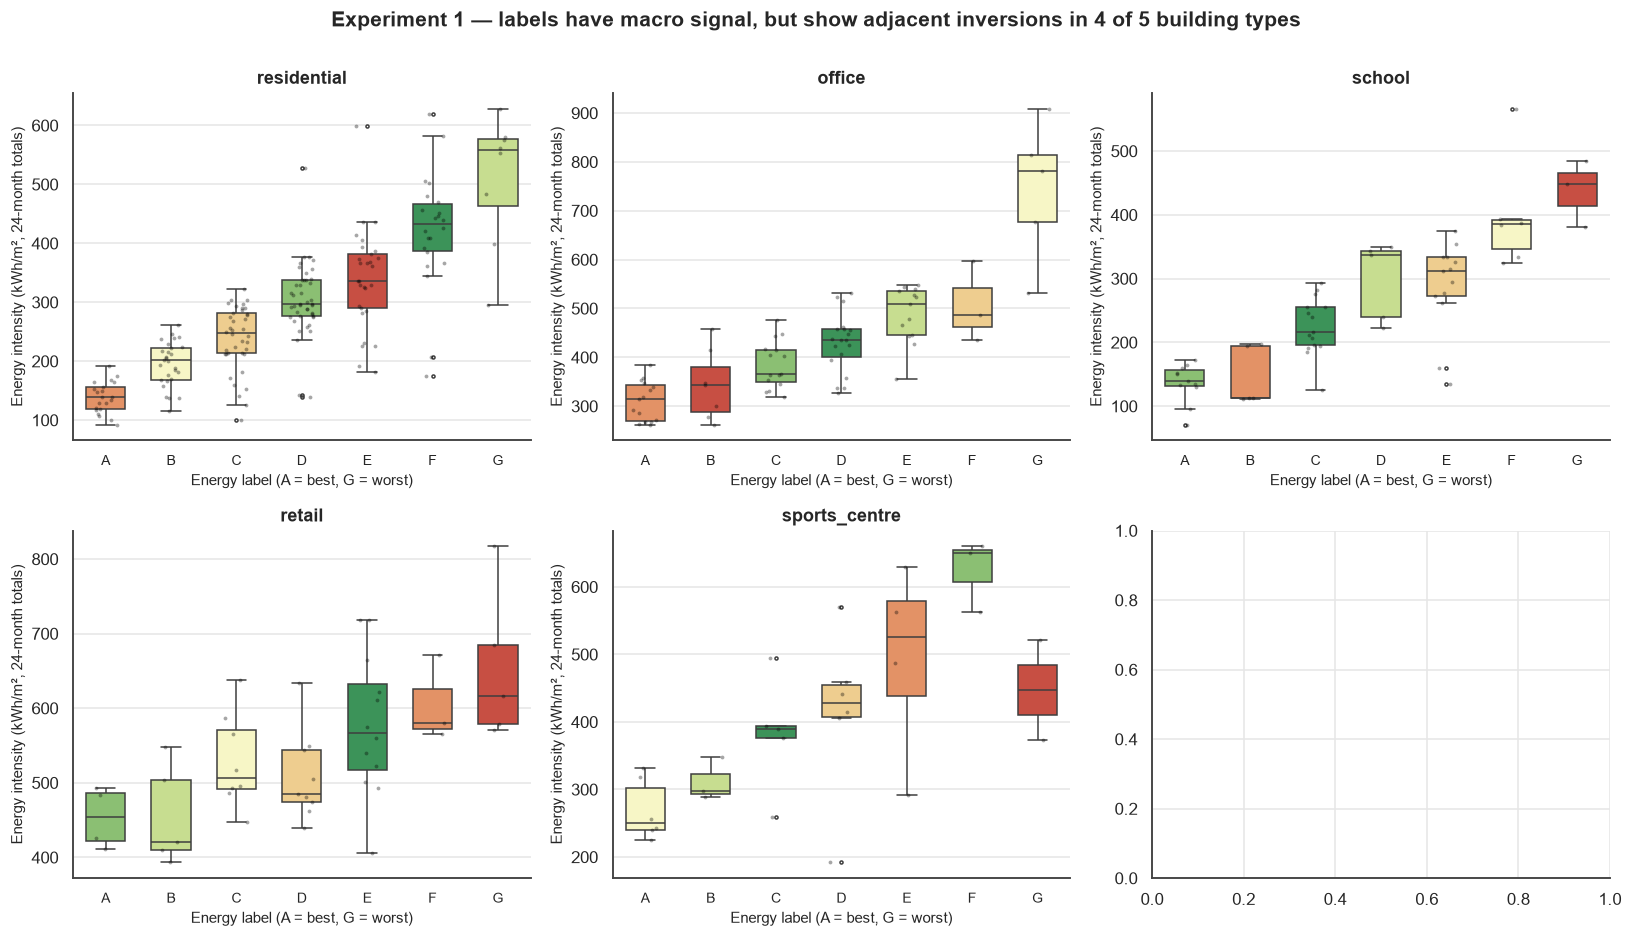

Saved: d:\Data Visualization\my_project\figures\static\exp1_labels.png


In [15]:
# Building-level intensity (label describes the building, not the month)
building_level = (
    df.groupby(["building_id", "building_type", "energy_label", "floor_area_m2"], dropna=False)
      .agg(total_energy_kwh=("Total_Energy", "sum"))
      .reset_index()
)
building_level["Energy_Intensity"] = building_level["total_energy_kwh"] / building_level["floor_area_m2"]

# Drop 'unknown' labels only for THIS chart
plot_df = building_level[building_level["energy_label"].isin(LABEL_ORDER)].copy()

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharey=False)
axes = axes.ravel()
for ax, btype in zip(axes, TYPE_ORDER):
    sub = plot_df[plot_df["building_type"] == btype]
    if sub.empty:
        ax.set_visible(False)
        continue
        
    # 🔧 修复点：显式添加 hue="energy_label" 和 legend=False
    sns.boxplot(data=sub, x="energy_label", y="Energy_Intensity",
                order=LABEL_ORDER, hue="energy_label", palette="RdYlGn_r", legend=False,
                width=0.6, fliersize=2, linewidth=1, ax=ax)
                
    # 叠加散点，让读者看到每一个真实的建筑（注意这里不需要传 hue，直接用纯色）
    sns.stripplot(data=sub, x="energy_label", y="Energy_Intensity",
                  order=LABEL_ORDER, color="black", size=2.5,
                  alpha=0.35, jitter=0.18, ax=ax)
                  
    ax.set_title(btype)
    ax.set_xlabel("Energy label (A = best, G = worst)")
    ax.set_ylabel("Energy intensity (kWh/m², 24-month totals)")
    ax.tick_params(axis="x", labelsize=9)

fig.suptitle("Experiment 1 — labels have macro signal, but show adjacent inversions in 4 of 5 building types",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
fig.savefig(FIG_DIR / "exp1_labels.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIG_DIR / 'exp1_labels.png'}")

## 2.2 SQ1 quantitative checks — monotonicity, overlap, unknown

The boxplot shows the shape, but SQ1 asks three specific questions:

1. **Monotonicity:** within each building type, do median intensity values fall A → G? We check this using an **adjacent inversion** count (how many times a label is more energy-intensive than the next worse label).
2. **Extremes:** are any A buildings worse than the median G building?
3. **Unknown labels:** are `unknown`-label buildings systematically different from assessed buildings?

The next cell answers these three questions with tables and one heatmap. We also display the sample size (`n`) for each cell because small samples (e.g., 2 buildings) can distort medians.

energy_label,A,B,C,D,E,F,G
building_type,,,,,,,
office,314.6,343.6,365.5,436.4,510.1,487.2,781.4
residential,139.1,201.2,248.3,297.0,336.1,432.5,558.2
retail,454.7,421.1,506.2,485.3,567.2,580.8,616.2
school,140.0,112.4,216.9,337.5,312.5,385.7,448.3
sports_centre,249.7,298.1,389.7,427.3,525.2,650.7,447.3


energy_label,A,B,C,D,E,F,G
building_type,,,,,,,
office,15,7,15,19,13,3,5
residential,21,28,38,43,29,22,8
retail,4,5,8,9,12,3,5
school,11,5,15,5,13,6,3
sports_centre,6,3,5,6,4,3,2


,adjacent_inversions,n_labels_present
building_type,,
office,1,7
residential,0,7
retail,2,7
school,2,7
sports_centre,1,7


,building_type,n_A,n_G,median_A,median_G,share_A_above_median_G
0,office,15,5,314.62,781.35,0.0
1,residential,21,8,139.10,558.24,0.0
2,retail,4,5,454.69,616.16,0.0
3,school,11,3,140.00,448.28,0.0
4,sports_centre,6,2,249.72,447.33,0.0


,building_type,n_unknown,median_unknown,n_assessed,median_assessed,difference_unknown_minus_assessed
0,office,3,401.06,77,415.16,-14.10
1,residential,11,206.88,189,278.45,-71.56
2,retail,4,434.70,46,531.14,-96.45
3,school,2,348.17,58,242.81,105.36
4,sports_centre,1,374.12,29,389.69,-15.57


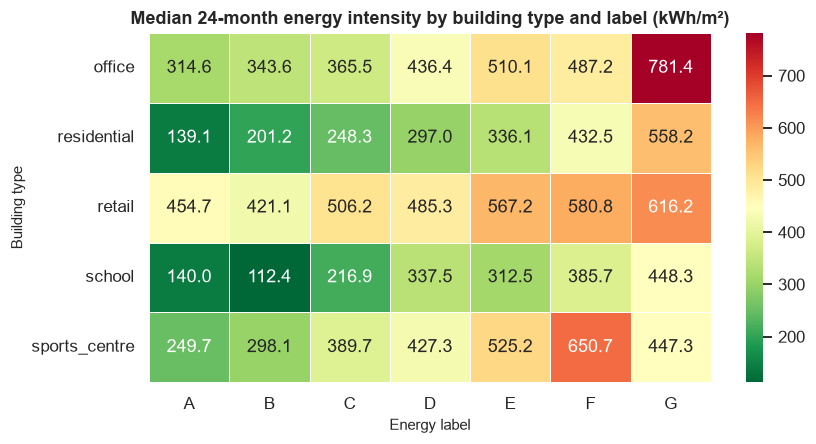

Saved: d:\Data Visualization\my_project\figures\static\exp1_label_median_heatmap.png


In [16]:
# SQ1 quantitative checks
assessed = building_level[building_level["energy_label"].isin(LABEL_ORDER)].copy()
unknown_df = building_level[building_level["energy_label"] == "unknown"].copy()

# 1) Median intensity by building_type × label
med = (
    assessed.pivot_table(index="building_type", columns="energy_label",
                         values="Energy_Intensity", aggfunc="median")
    .reindex(columns=LABEL_ORDER)
)
display(med.round(1))

# Count of buildings behind each median (small n is a caveat)
n_by_type_label = (
    assessed.pivot_table(index="building_type", columns="energy_label",
                         values="building_id", aggfunc="nunique")
    .reindex(columns=LABEL_ORDER)
)
display(n_by_type_label.fillna(0).astype(int))

# 2) Adjacent inversions: how many times median(label_i) > median(label_{i+1})
def n_adjacent_inversions(row):
    vals = row.dropna().values
    return sum(vals[i] > vals[i + 1] for i in range(len(vals) - 1))

inv = med.apply(n_adjacent_inversions, axis=1).to_frame("adjacent_inversions")
inv["n_labels_present"] = med.notna().sum(axis=1)
display(inv)

# 3) Overlap indicator: share of A buildings above the same-type median G building
overlap_rows = []
for btype, sub in assessed.groupby("building_type"):
    a_vals = sub.loc[sub["energy_label"] == "A", "Energy_Intensity"]
    g_vals = sub.loc[sub["energy_label"] == "G", "Energy_Intensity"]
    overlap_rows.append({
        "building_type": btype,
        "n_A": len(a_vals),
        "n_G": len(g_vals),
        "median_A": a_vals.median() if len(a_vals) else np.nan,
        "median_G": g_vals.median() if len(g_vals) else np.nan,
        "share_A_above_median_G": (a_vals > g_vals.median()).mean() if len(a_vals) and len(g_vals) else np.nan,
    })
overlap = pd.DataFrame(overlap_rows).sort_values("building_type")
display(overlap.round(2))

# 4) Unknown-label buildings vs assessed buildings, by type
unknown_summary = (
    unknown_df.groupby("building_type")["Energy_Intensity"]
    .agg(n_unknown="count", median_unknown="median")
    .reset_index()
)
assessed_summary = (
    assessed.groupby("building_type")["Energy_Intensity"]
    .agg(n_assessed="count", median_assessed="median")
    .reset_index()
)
unknown_compare = unknown_summary.merge(assessed_summary, on="building_type", how="outer")
unknown_compare["difference_unknown_minus_assessed"] = (
    unknown_compare["median_unknown"] - unknown_compare["median_assessed"]
)
display(unknown_compare.round(2))

# 5) Heatmap of medians (static export)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(med, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=0.5, ax=ax)
ax.set_title("Median 24-month energy intensity by building type and label (kWh/m²)")
ax.set_xlabel("Energy label")
ax.set_ylabel("Building type")
plt.tight_layout()
fig.savefig(FIG_DIR / "exp1_label_median_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIG_DIR / 'exp1_label_median_heatmap.png'}")

### ✍️ Observe #2

1. In the **residential** panel, the medians fall perfectly A → G (0 inversions). This shows the label system is not completely random.
2. Look at **school**: median B (112.4) is *lower* than median A (140.0). Look at **sports_centre**: median G (447.3) is *much lower* than median F (650.7). 
3. Look at the `n` table: sports_centre G has only 2 buildings, school G has 3. The extreme labels in some types are based on tiny samples, which makes relying on them for investment highly risky.

## 2.3 Finding & business meaning

**The energy label has macro-level signal, but it is not a reliable building-level investment ranking.**

- The label is not random. In **residential** buildings, the median intensity rises perfectly monotonically from A (139 kWh/m²) to G (558 kWh/m²) with zero inversions.
- However, the order breaks down in the other four building types. We observe **adjacent inversions**: 
  - In **school**, B is better than A.
  - In **sports_centre**, G is better than F and E.
  - In **retail**, A is worse than B, and C is worse than D.
- The extreme comparison (`share_A_above_median_G`) is exactly 0 across all types: no A building is worse than the median G building. **The problem is not A vs G extremes, but the chaotic middle**. If the council uses the label to target "B or C" buildings, it will misidentify which ones actually need renovation.
- Furthermore, some label groups have **tiny sample sizes** (e.g., retail A has 4 buildings, sports_centre G has 2). Their medians are highly sensitive to individual outliers. 
- `unknown`-label buildings also behave differently by type (e.g., in school they are worse than assessed, but in residential they are better), meaning they cannot be assumed to be a uniform group.

**Decision rule for the 2030 budget:** do **not** rank buildings by `energy_label` alone.
Rank them by **measured energy intensity**, and combine it with the retrofit and solar evidence from B and C. The label can stay as a secondary filter, but because adjacent labels frequently invert, it is unsafe to use it as the primary ranking key.

## 2.4 Hand-off to B and C

Everything below is already done in Part 1 — please **do not re-clean**.

| Variable | What it is | How B/C should use it |
|---|---|---|
| `df` | Clean building-month panel (one row = one building-month) | Use directly; do **not** recompute `Total_Energy` or `Energy_Intensity` |
| `df["Energy_Intensity"]` | `Total_Energy / floor_area_m2` **at the month level** | For time-series charts (B) |
| `building_summary` | One row per building, 24-month totals and `energy_intensity_kwh_m2` | For cross-sectional charts (B's retrofit before/after) and C's dashboard ranking |
| `building_summary["has_retrofit"]` | `True` if `retrofit_date` is not empty | B's pre/post split |
| `building_summary["solar_share_of_electricity"]` | `solar_kwh / (electricity_kwh + solar_kwh)` over the two years | B's solar analysis, C's dashboard |
| `BI_DIR/building_monthly_clean.csv` | The whole panel, clean | Power BI fact table |
| `BI_DIR/building_summary.csv` | One row per building | Power BI dimension + measure table |
| `BI_DIR/district_summary.csv` | One row per district, with **weighted** intensity `sum(energy)/sum(floor area)` and per-capita rate | Power BI map, per-1000-residents indicators |

**Rules B and C must respect**
1. **Label is a weak filter**: As shown in 2.2, do not assume that a B-labelled building uses less energy than an A-labelled building, or that F is always worse than G. Always use measured `Energy_Intensity` for sorting.
2. **Never** re-clean `df` — re-running A's cells is enough.
3. If B or C aggregate `Energy_Intensity` **across buildings**, use
   `sum(Total_Energy) / sum(floor_area_m2)` (a **ratio of sums**), never `mean(Energy_Intensity)`.
   The brief says this explicitly.
   `district_summary["mean_energy_intensity"]` is already a **weighted** intensity (`sum energy / sum floor area`). Do not average it again.
4. The `retrofit_date` column is a `YYYY-MM` string — cast it with
   `pd.to_datetime(building_summary["retrofit_date"] + "-01")` if you need dates.
5. On any Plotly map, hide the world basemap: `fig.update_geos(visible=False)`.
   Meridia is fictional.
6. **Before every submission**, run **Restart & Run All** and check
   `figures/static/`, `figures/interactive/`, `bi_export/` each contain the expected files.